<a href="https://colab.research.google.com/github/AleAsesino/mineriaDatosAnomaliasABCcarreteras/blob/main/preprocesamientoABCV1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Preprocesamiento**

In [7]:
install.packages("dbscan")

library(tidyverse)
library(lubridate)
library(dbscan)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
# 1. Cargar dataset
df_raw <- read_csv("data.csv", show_col_types = FALSE)

# 2. Limpieza y creación de variables base
df_clean <- df_raw %>%
  mutate(
    fecha_reporte = ymd_hms(fecha_reporte, quiet = TRUE),
    fecha_fin     = ymd_hms(fecha_fin, quiet = TRUE),
    dia           = as_date(fecha_reporte),
    duracion_h    = as.numeric(difftime(fecha_fin, fecha_reporte, units = "hours")),
    estado_lower  = str_to_lower(coalesce(estado, "")),
    es_bloqueo    = if_else(str_detect(estado_lower, "no transitable|restriccion|corte"), 1L, 0L)
  ) %>%
  filter(
    !is.na(dia),
    is.na(duracion_h) | (duracion_h >= 0 & duracion_h <= 2000)
  )

# 3. Agregación diaria (Dataset analítico 2D)
df_diario <- df_clean %>%
  group_by(dia) %>%
  summarise(
    total_bloqueos      = sum(es_bloqueo, na.rm = TRUE),
    duracion_promedio_h = mean(duracion_h, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  mutate(
    duracion_promedio_h = replace_na(duracion_promedio_h, median(duracion_promedio_h, na.rm = TRUE))
  ) %>%
  drop_na()

# 4. Estandarización (Z-score) de las 2 variables numéricas para LOF y Gaussiana
X_scaled <- df_diario %>%
  select(total_bloqueos, duracion_promedio_h) %>%
  scale() %>%
  as.matrix()

# 5. Exportar dataset preprocesado a CSV
write_csv(df_diario, "df_diario_preprocesado.csv")
cat("Archivo guardado: df_diario_preprocesado.csv (", nrow(df_diario), " filas)\n", sep = "")

head(df_diario)

Archivo guardado: df_diario_preprocesado.csv (2267 filas)


dia,total_bloqueos,duracion_promedio_h
<date>,<int>,<dbl>
2020-08-13,7,63.66365
2020-08-14,5,63.29750
2020-08-15,21,36.77681
2020-08-16,14,39.75857
2020-08-17,9,35.56574
2020-08-18,8,33.83753


Anomalías detectadas (Gaussiana): 102 


dia,total_bloqueos,duracion_promedio_h,dist_mahalanobis,anomalia_gauss
<date>,<int>,<dbl>,<dbl>,<lgl>
2024-08-01,196,8.110529,381.71455,TRUE
2021-11-26,6,81.660227,63.36599,TRUE
2023-03-24,81,18.439258,58.78176,TRUE
2023-06-17,2,78.883241,56.24632,TRUE
2023-03-31,80,11.381633,54.97318,TRUE
2024-09-27,3,74.745500,48.61455,TRUE
2024-01-25,75,7.390094,47.20703,TRUE
2025-06-09,74,13.057639,46.39019,TRUE
2021-01-12,73,17.074170,46.04145,TRUE


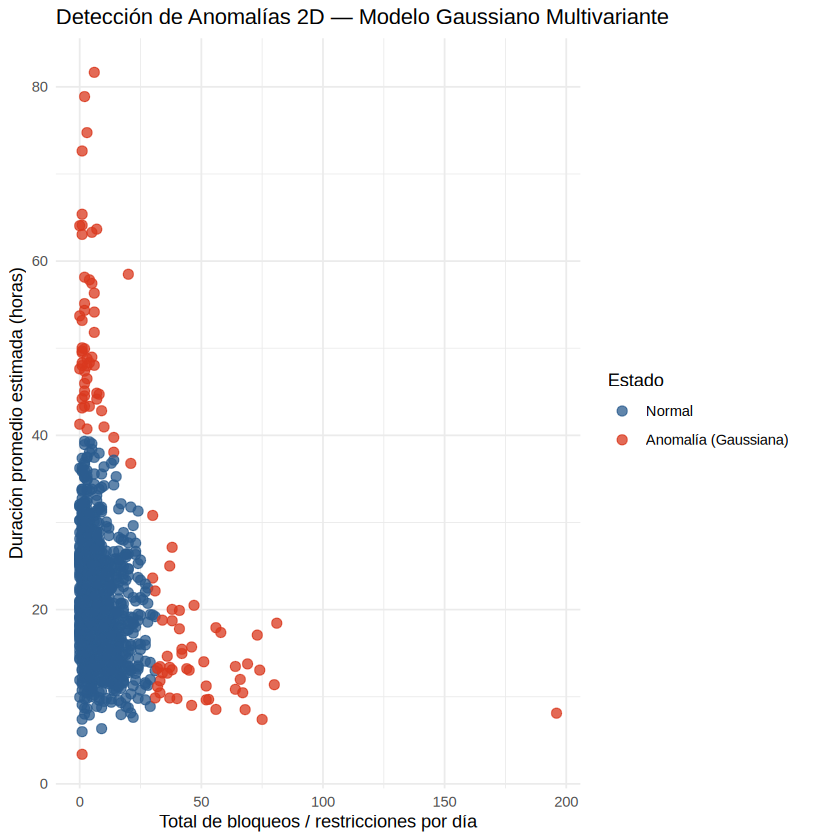

In [ ]:
# 1. Estimar media (mu) y matriz de covarianza (Sigma)
mu <- colMeans(X_scaled)
sigma <- cov(X_scaled)

# 2. Calcular distancia de Mahalanobis al cuadrado y densidad Gaussiana
d2 <- mahalanobis(X_scaled, center = mu, cov = sigma)
k <- ncol(X_scaled) # 2 variables

# Valor p bajo distribución Chi-cuadrado (probabilidad de observar un punto tan o más extremo)
p_valor_gauss <- pchisq(d2, df = k, lower.tail = FALSE)

# Umbral: 5% más anómalo (p < 0.05)
df_diario <- df_diario %>%
  mutate(
    dist_mahalanobis = d2,
    anomalia_gauss   = p_valor_gauss < 0.05
  )

# Ver resumen de anomalías Gaussianas
cat("Anomalías detectadas (Gaussiana):", sum(df_diario$anomalia_gauss), "\n")
df_diario %>% filter(anomalia_gauss) %>% arrange(desc(dist_mahalanobis)) %>% head(10)

# Gráfico de puntos 2D - Método Gaussiano
ggplot(df_diario, aes(x = total_bloqueos, y = duracion_promedio_h, color = anomalia_gauss)) +
  geom_point(alpha = 0.75, size = 2.5) +
  scale_color_manual(
    values = c("FALSE" = "#2b5c8f", "TRUE" = "#d9381e"),
    labels = c("Normal", "Anomalía (Gaussiana)")
  ) +
  labs(
    title = "Detección de Anomalías 2D — Modelo Gaussiano Multivariante",
    x = "Total de bloqueos / restricciones por día",
    y = "Duración promedio estimada (horas)",
    color = "Estado"
  ) +
  theme_minimal()

Anomalías detectadas (LOF): 97 


dia,total_bloqueos,duracion_promedio_h,dist_mahalanobis,anomalia_gauss,score_lof,anomalia_lof
<date>,<int>,<dbl>,<dbl>,<lgl>,<dbl>,<lgl>
2024-08-01,196,8.110529,381.7145507,TRUE,7.714163,TRUE
2022-06-12,0,25.124833,0.6916360,FALSE,2.829965,TRUE
2024-08-25,0,24.794167,0.6686504,FALSE,2.806805,TRUE
2024-07-27,0,25.164167,0.6946268,FALSE,2.530729,TRUE
2020-11-21,1,3.391389,7.0863936,TRUE,2.386183,TRUE
2025-06-02,20,58.488300,29.4095124,TRUE,2.229404,TRUE
2020-12-09,1,26.757500,0.7414074,FALSE,2.049063,TRUE
2022-01-16,0,25.180139,0.6958568,FALSE,2.043085,TRUE
2021-11-26,6,81.660227,63.3659911,TRUE,2.034902,TRUE


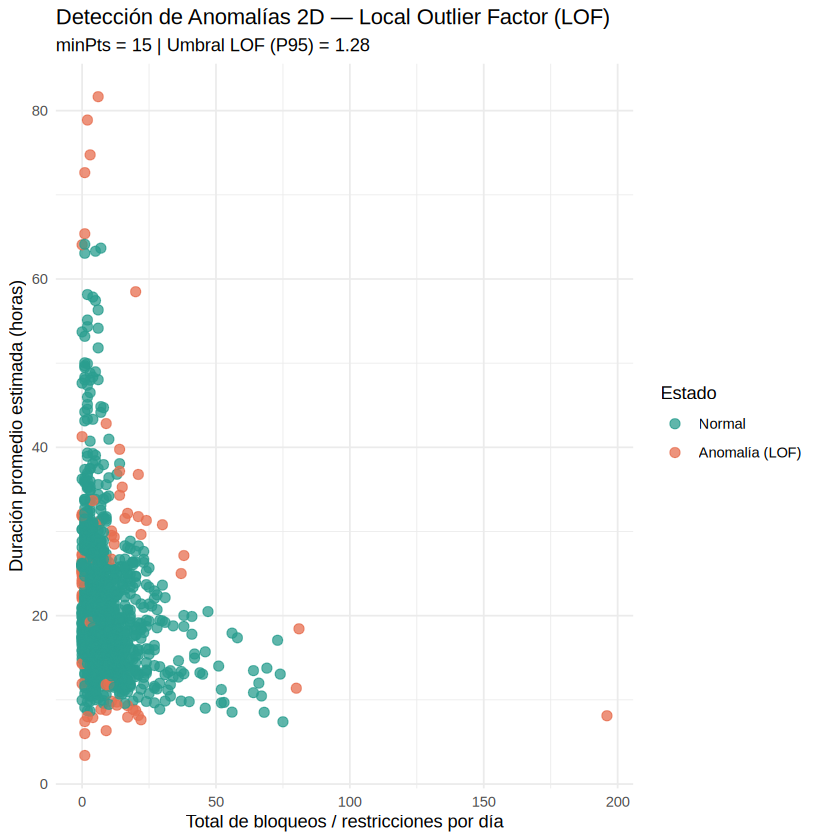

In [ ]:
# 1. Calcular LOF (minPts = 15 vecinos es un buen punto de partida para datos diarios)
lof_scores <- lof(X_scaled, minPts = 15)

# 2. Definir umbral (por ejemplo, LOF > 1.5 o el percentil 95)
umbral_lof <- quantile(lof_scores, 0.95)

df_diario <- df_diario %>%
  mutate(
    score_lof    = lof_scores,
    anomalia_lof = score_lof > umbral_lof
  )

# Ver resumen de anomalías LOF
cat("Anomalías detectadas (LOF):", sum(df_diario$anomalia_lof), "\n")
df_diario %>% filter(anomalia_lof) %>% arrange(desc(score_lof)) %>% head(10)

# Gráfico de puntos 2D - Método LOF
ggplot(df_diario, aes(x = total_bloqueos, y = duracion_promedio_h, color = anomalia_lof)) +
  geom_point(alpha = 0.75, size = 2.5) +
  scale_color_manual(
    values = c("FALSE" = "#2a9d8f", "TRUE" = "#e76f51"),
    labels = c("Normal", "Anomalía (LOF)")
  ) +
  labs(
    title = "Detección de Anomalías 2D — Local Outlier Factor (LOF)",
    subtitle = paste0("minPts = 15 | Umbral LOF (P95) = ", round(umbral_lof, 2)),
    x = "Total de bloqueos / restricciones por día",
    y = "Duración promedio estimada (horas)",
    color = "Estado"
  ) +
  theme_minimal()